<table style="width: 100%; margin-left: auto; margin-right: auto; background-color: white;">
<tbody>
<tr>

<td style="text-align: center; width: 12%;"><img src=img/brasil-brasao.png alt="" /></td>

<td style="width: 68%;">
<h2 style="text-align: center; margin-top: 1%;">Rep&uacute;blica Federativa do Brasil</h2>
<h2 style="text-align: center; margin-top: 1%;">Minist&eacute;rio da Educa&ccedil;&atilde;o</h2>
<h2 style="text-align: center; margin-top: 1%;">Universidade Federal do Amazonas</h2>
<h2 style="text-align: center; margin-top: 1%;">Instituto de Computa&ccedil;&atilde;o</h2>
</td>

<td style="width: 12%;"><img src="img/UFAM-logo.png" alt="" /></td>

</tr>
</tbody>
</table>

---

# Ciência de Dados

## Trabalho Prático I: Exploração de Dados, v 1.0

_Professor Dr. Marco Cristo_


**Alunos:** `JULIO CESAR CERRATE CASTRO, MICAEL GERRAR DA SILVA BARBOSA e ERIK FELIPE DA SILVA OLIVEIRA` <br>
**E-mail:** `julio.cesar@icomp.ufam.edu.br, micael.gerrar@icomp.ufam.edu.br e erikf.oliveira@icomp.ufam.edu.br`


#### Sobre os dados

Este trabalho usa os microdados da Amostra do Censo Demográfico 2010 (IBGE), com foco no tema **Trabalho e Rendimento**. Cada equipe (este trabalho é para trios) trabalha sobre a população do seu **município** (especificado para a equipe) e a compara com o restante do país. Consulte o notebook `Dicionário de dados.ipynb` para a descrição de cada variável.

**Atenção**: por motivos didáticos, a base de dados contém alguns nulos e inconsistências propositalmente introduzidas (além dos nulos que já ocorrem naturalmente por questões de desenho da pesquisa do IBGE) — parte do seu trabalho na seção de Qualidade de Dados é justamente encontrá-los e tratá-los.


#### Preliminares


In [411]:
%pip install matplotlib numpy pandas seaborn scipy scikit-learn pyarrow

Note: you may need to restart the kernel to use updated packages.


In [412]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import sklearn
import sys
import os

In [413]:
print("Python", sys.version)
print("--------")
print("Pandas:", pd.__version__)
print("Numpy:", np.__version__)
print("SKLearn:", sklearn.__version__)
pd.set_option('display.max_rows', None)

Python 3.13.5 (main, Aug 10 2026, 12:06:59) [GCC 14.2.0]
--------
Pandas: 3.0.6
Numpy: 2.5.4
SKLearn: 1.9.1


Escolha o arquivo de dados com o seu nome no diretório `data`.


In [414]:
DATA_PQT = 'data/censo2010_pessoas.parquet'
MUNICIPIO = 'São Bernardo do Campo' # Use o que foi especificado para sua equipe
SIGLA_UF = 'SP'      # Sigla da UF do município acima 

In [415]:
# Caminho do arquivo
df_censo = pd.read_parquet(DATA_PQT)

# Manter somente São Bernardo do Campo, em São Paulo.
df_censo = df_censo.loc[
    (df_censo["NOME_MUNICIPIO"] == MUNICIPIO)
    & (df_censo["SIGLA_UF"] == SIGLA_UF)
].copy()

# Conferir a estrutura dos dados do município.
df_censo.info()



<class 'pandas.DataFrame'>
RangeIndex: 37593 entries, 3168586 to 3206178
Data columns (total 45 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   COD_UF                          37593 non-null  str    
 1   COD_MUNICIPIO_UF                37593 non-null  str    
 2   AREA_PONDERACAO                 37593 non-null  str    
 3   V0300                           37593 non-null  int64  
 4   PESO_AMOSTRAL                   37593 non-null  float64
 5   SEXO                            37593 non-null  str    
 6   IDADE                           37593 non-null  int64  
 7   COR_RACA                        36833 non-null  str    
 8   NIVEL_INSTRUCAO                 36887 non-null  str    
 9   COND_ATIVIDADE                  32735 non-null  str    
 10  COND_OCUPACAO                   20316 non-null  str    
 11  SITUACAO_OCUPACAO               32735 non-null  str    
 12  POSICAO_OCUPACAO                186

---

#### Qualidade de dados


<div class="alert alert-info">
    <b>(0,2) 1</b> - Quais colunas possuem campos nulos em <code>df_censo</code>? Ordene-as da que tem mais nulos para a que tem menos.
</div>


In [416]:
## Contar os valores nulos de cada coluna.
quantidade_nulos = df_censo.isna().sum()

# Selecionar as colunas com nulos e ordenar da maior
# quantidade para a menor.
colunas_com_nulos = (
    quantidade_nulos[quantidade_nulos > 0]
    .sort_values(ascending=False)
)

# Apresentar as contagens em uma tabela.
display(colunas_com_nulos.to_frame(name="Quantidade de nulos"))

,Quantidade de nulos
SUBGRUPO_OCUPACAO,22701
RENDA_BRUTA_TRAB_PRINCIPAL,19199
COD_OCUPACAO,18976
RENDA_TODOS_TRABALHOS_SM,18976
HORAS_TRABALHADAS_SEMANA,18976
RENDA_TODOS_TRABALHOS,18976
POSICAO_OCUPACAO,18976
COD_ATIVIDADE_ECON,18976
RENDA_TRAB_PRINCIPAL,18976
COND_OCUPACAO,17277


As colunas do DataFrame df_censo que possuem campos nulos, ordenadas da maior quantidade para a menor, são: SUBGRUPO_OCUPACAO (22.701), RENDA_BRUTA_TRAB_PRINCIPAL (19.199), HORAS_TRABALHADAS_SEMANA, COD_ATIVIDADE_ECON, COD_OCUPACAO, POSICAO_OCUPACAO, RENDA_TODOS_TRABALHOS, RENDA_TODOS_TRABALHOS_SM e RENDA_TRAB_PRINCIPAL (18.976 cada), COND_OCUPACAO (17.277), TEM_INTERNET (13.141), COND_ATIVIDADE, SITUACAO_OCUPACAO, RENDA_TOTAL_SM e RENDA_TOTAL (4.858 cada), COR_RACA (760), RENDA_DOMICILIAR_PER_CAPITA (730), NIVEL_INSTRUCAO (706), ESGOTAMENTO_SANITARIO (209) e DESTINO_LIXO (192).


<div class="alert alert-primary">
<b>(0,1) 1.1</b> - Várias dessas colunas têm nulos pelo mesmo motivo: o questionário do Censo pula perguntas que não se aplicam a quem responde (ex.: perguntas sobre o trabalho não fazem sentido para quem não trabalha). Escolha três colunas com muitos nulos e explique, olhando o dicionário de dados, por que elas têm nulos "estruturais" (que não são erro, mas sim ausência de aplicabilidade da pergunta).
</div>


SUBGRUPO_OCUPACAO (22.701 nulos): essa variável identifica o subgrupo da ocupação profissional. Os valores podem estar ausentes porque a pergunta se aplica somente a pessoas com ocupação que possa ser classificada nessa categoria.
RENDA_BRUTA_TRAB_PRINCIPAL (19.199 nulos): essa variável registra a renda bruta recebida no trabalho principal. Para pessoas que não possuem trabalho principal, a pergunta não se aplica, o que pode explicar a ausência de informações.
HORAS_TRABALHADAS_SEMANA (18.976 nulos): essa variável registra a quantidade de horas trabalhadas por semana. Para pessoas que não exerceram trabalho no período de referência, essa informação pode não ser aplicável, resultando em valores nulos.


<div class="alert alert-info">
<b>(0,25) 2</b> - Investigue a relação entre <code>IDADE</code> e os nulos em <code>RENDA_TOTAL</code>. Existe um padrão claro? Baseado nisso, decida um critério de idade mínima para manter no conjunto de dados e remova as instâncias fora desse critério.
</div>

<i>Dica</i>: compare a distribuição de <code>IDADE</code> entre quem tem <code>RENDA_TOTAL</code> nulo e quem não tem.


In [417]:
# Calcular o percentual de renda nula em cada idade.
percentual_nulos = (
    df_censo.groupby("IDADE")["RENDA_TOTAL"]
    .apply(lambda renda: renda.isna().mean() * 100)
)

display(
    percentual_nulos.to_frame(name="Percentual de renda nula (%)")
)

,Percentual de renda nula (%)
IDADE,
0,100.0
1,100.0
2,100.0
3,100.0
4,100.0
5,100.0
6,100.0
7,100.0
8,100.0


In [418]:
idade_minima = 10

# Quantidade de registros antes da filtragem
total_antes = len(df_censo)

# Remover registros com idade inferior a 10 anos
df_censo = df_censo[df_censo['IDADE'] >= idade_minima].copy()

# Quantidade de registros removidos
removidos = total_antes - len(df_censo)

# Log da operação
print("=== FILTRAGEM POR IDADE ===")
print(f"Idade mínima adotada: {idade_minima} anos")
print(f"Registros antes: {total_antes}")
print(f"Registros removidos: {removidos}")
print(f"Registros restantes: {len(df_censo)}")

=== FILTRAGEM POR IDADE ===
Idade mínima adotada: 10 anos
Registros antes: 37593
Registros removidos: 4849
Registros restantes: 32744


<div class="alert alert-primary">
<b>(0,15) 2.1</b> - Depois de aplicar o filtro acima, ainda restam nulos em <code>RENDA_TOTAL</code>? Se sim, quantos, e o que isso sugere?
</div>


In [419]:

nulos_restantes = df_censo['RENDA_TOTAL'].isnull().sum()

print("=== VERIFICAÇÃO DE NULOS ===")
print(f"Nulos restantes em RENDA_TOTAL: {nulos_restantes}")

if nulos_restantes > 0:
    print("Ainda existem valores nulos após o filtro.")
    print("Isso sugere que os nulos também podem estar relacionados")
    print("a outros fatores além da idade.")
else:
    print("Não restam valores nulos em RENDA_TOTAL.")

=== VERIFICAÇÃO DE NULOS ===
Nulos restantes em RENDA_TOTAL: 9
Ainda existem valores nulos após o filtro.
Isso sugere que os nulos também podem estar relacionados
a outros fatores além da idade.


Após aplicar o filtro de idade mínima de 10 anos, ainda restaram **9 valores nulos** na coluna `RENDA_TOTAL`. Isso sugere que a ausência de dados não está relacionada exclusivamente à idade, podendo também estar associada a outros fatores, como a situação ocupacional dos entrevistados ou a falta de informações sobre a renda. Portanto, o filtro reduziu os valores nulos, mas não eliminou completamente o problema.


<div class="alert alert-info">
<b>(0,3) 3</b> - Verifique se há valores de <code>IDADE</code> ou <code>SEXO</code> fora do domínio esperado pelo dicionário de dados (idades implausíveis, códigos de sexo diferentes de 1/2). Trate essas inconsistências.
</div>


In [420]:

# Verificar valores inconsistentes
print("=== VERIFICAÇÃO DE INCONSISTÊNCIAS ===")

# Verificar idades fora do intervalo plausível
idades_invalidas = df_censo[
    (df_censo["IDADE"] < 0) | (df_censo["IDADE"] > 140)
]

print(f"Registros com idade inválida: {len(idades_invalidas)}")

# Verificar códigos de sexo diferentes de 1 e 2
sexos_invalidos = df_censo[
    ~df_censo['SEXO'].astype(str).isin(['1', '2'])
]

print(f"Registros com sexo inválido: {len(sexos_invalidos)}")

# Remover registros inconsistentes
df_censo = df_censo[
    df_censo["IDADE"].between(0, 140) &
    df_censo['SEXO'].astype(str).isin(['1', '2'])
].copy()

print("\n=== TRATAMENTO CONCLUÍDO ===")
print(f"Registros restantes: {len(df_censo)}")
print("Foram removidos registros com idade fora do intervalo")
print("de 0 a 140 anos ou código de sexo diferente de 1 e 2.")

=== VERIFICAÇÃO DE INCONSISTÊNCIAS ===
Registros com idade inválida: 73
Registros com sexo inválido: 63

=== TRATAMENTO CONCLUÍDO ===
Registros restantes: 32608
Foram removidos registros com idade fora do intervalo
de 0 a 140 anos ou código de sexo diferente de 1 e 2.


<div class="alert alert-info">
<b>(0,2) 4</b> - Verifique se há linhas completamente duplicadas em <code>df_censo</code>. Remova-as.
</div>


In [421]:

# Verificar linhas completamente duplicadas
duplicadas = df_censo.duplicated().sum()

print("=== VERIFICAÇÃO DE DUPLICATAS ===")
print(f"Linhas duplicadas encontradas: {duplicadas}")

# Remover linhas duplicadas
df_censo = df_censo.drop_duplicates().copy()

print(f"Linhas restantes após a remoção: {len(df_censo)}")
print("Remoção de duplicatas concluída.")

=== VERIFICAÇÃO DE DUPLICATAS ===
Linhas duplicadas encontradas: 200
Linhas restantes após a remoção: 32408
Remoção de duplicatas concluída.


<div class="alert alert-info">
<b>(0,3) 5</b> - Compare <code>RENDA_TOTAL</code> com <code>RENDA_TODOS_TRABALHOS</code> (que deveria ser sempre menor ou igual, já que a primeira soma a segunda com outras rendas). Identifique casos em que <code>RENDA_TOTAL</code> é muito maior que <code>RENDA_TODOS_TRABALHOS</code> (ex.: mais de 10x mais alta) -- um padrão consistente com erro de digitação (ex.: vírgula decimal digitada no lugar errado). Corrija esses casos.
</div>


In [422]:

# Selecionar registros com rendas preenchidas e renda de trabalho positiva
validos = (
    df_censo['RENDA_TOTAL'].notna() &
    df_censo['RENDA_TODOS_TRABALHOS'].notna() &
    (df_censo['RENDA_TODOS_TRABALHOS'] > 0)
)

# Identificar possíveis inconsistências: renda total > 10x renda de trabalhos
suspeitos = validos & (
    df_censo['RENDA_TOTAL'] >
    10 * df_censo['RENDA_TODOS_TRABALHOS']
)

print("=== POSSÍVEIS ERROS DE RENDA ===")
print(f"Casos identificados: {suspeitos.sum()}")

# Exibir os primeiros casos para inspeção
print(df_censo.loc[
    suspeitos,
    ['RENDA_TOTAL', 'RENDA_TODOS_TRABALHOS']
].head(20))

# Verificar se a divisão por 100 é sustentada
# pela renda registrada em salários mínimos.
renda_corrigida = df_censo['RENDA_TOTAL'] / 100
renda_trabalho = df_censo['RENDA_TODOS_TRABALHOS']
renda_conforme_sm = df_censo['RENDA_TOTAL_SM'] * 510

proximos = (
    suspeitos &
    df_censo['RENDA_TOTAL_SM'].notna() &
    np.isclose(
        renda_corrigida,
        renda_conforme_sm,
        rtol=0,
        atol=0.01
    ) &
    (renda_corrigida >= renda_trabalho)
)

print(f"Casos candidatos à correção: {proximos.sum()}")

# Corrigir os casos candidatos
quantidade_corrigida = proximos.sum()
df_censo.loc[proximos, 'RENDA_TOTAL'] /= 100

print(f"Registros corrigidos: {quantidade_corrigida}")

# Verificar novamente as inconsistências
validos = (
    df_censo['RENDA_TOTAL'].notna() &
    df_censo['RENDA_TODOS_TRABALHOS'].notna() &
    (df_censo['RENDA_TODOS_TRABALHOS'] > 0)
)

inconsistencias = validos & (
    df_censo['RENDA_TOTAL'] >
    10 * df_censo['RENDA_TODOS_TRABALHOS']
)

quantidade = inconsistencias.sum()

print("\n=== VERIFICAÇÃO APÓS A CORREÇÃO ===")
print(f"Casos suspeitos restantes: {quantidade}")

if quantidade == 0:
    print("Nenhum caso acima do limite de 10x foi encontrado.")
else:
    print("Ainda existem casos acima de 10 vezes.")
    print("Esses casos não são erros e foram preservados.")
    print(df_censo.loc[
        inconsistencias,
        ['RENDA_TOTAL', 'RENDA_TODOS_TRABALHOS']
    ])

=== POSSÍVEIS ERROS DE RENDA ===
Casos identificados: 53
         RENDA_TOTAL  RENDA_TODOS_TRABALHOS
3169124     130000.0                 1300.0
3170755      12510.0                  510.0
3171552       3286.0                  286.0
3173936      55000.0                  550.0
3174348      38000.0                  380.0
3174516        430.0                   30.0
3175010     150000.0                 1500.0
3175472       9800.0                  800.0
3176014     204100.0                 1020.0
3176554      58000.0                  580.0
3177178     120000.0                 1200.0
3177948      60000.0                  600.0
3178280        560.0                   50.0
3178640     150000.0                 1500.0
3180020       1850.0                  120.0
3181075      12800.0                  800.0
3181867      22200.0                 2200.0
3182434      75000.0                  750.0
3183923      28000.0                  280.0
3184394       1140.0                  100.0
Casos candidatos à 

Foram identificados 53 registros em que a renda total ultrapassava 10 vezes a renda de todos os trabalhos. Em 30 deles, a divisão da renda total por 100 apresentou concordância com o valor registrado em salários mínimos, considerando o salário mínimo de R$ 510,00 e uma tolerância de um centavo para arredondamento. Esses registros foram corrigidos, mantendo a renda total maior ou igual à renda dos trabalhos. Os 23 casos restantes foram preservados, pois uma diferença elevada entre essas rendas não comprova, isoladamente, erro de digitação.

<div class="alert alert-info">
<b>(0,5) 6</b> - Ainda restam nulos em <code>RENDA_TOTAL</code> (o resíduo identificado na questão 2.1) e em <code>COR_RACA</code>, <code>NIVEL_INSTRUCAO</code> e <code>RENDA_DOMICILIAR_PER_CAPITA</code>. Decida e aplique uma estratégia de tratamento para cada uma, justificando sua escolha.
</div>

<i>Dica</i>: nem toda coluna precisa do mesmo tratamento -- pense se faz mais sentido remover a linha, imputar um valor, ou criar uma categoria "não informado".


In [423]:
colunas = [
    "RENDA_TOTAL",
    "COR_RACA",
    "NIVEL_INSTRUCAO",
    "RENDA_DOMICILIAR_PER_CAPITA"
]

# Mostrar os nulos antes do tratamento.
print("=== NULOS ANTES DO TRATAMENTO ===")
print(df_censo[colunas].isna().sum())

# Remover registros que ainda tenham renda total ausente.
total_antes = len(df_censo)

df_censo = df_censo.dropna(
    subset=["RENDA_TOTAL"]
).copy()

print(
    f"\nRegistros removidos por renda total nula: "
    f"{total_antes - len(df_censo)}"
)

# Preservar os registros de raça e cor
df_censo["COR_RACA"] = (
    df_censo["COR_RACA"].fillna("Não informado")
)

# Preservar os registros sem informação de escolaridade.
df_censo["NIVEL_INSTRUCAO"] = (
    df_censo["NIVEL_INSTRUCAO"].fillna("Não informado")
)

# 4. Preencher renda domiciliar per capita com a mediana
mediana_per_capita = (
    df_censo["RENDA_DOMICILIAR_PER_CAPITA"].median()
)

df_censo["RENDA_DOMICILIAR_PER_CAPITA"] = (
    df_censo["RENDA_DOMICILIAR_PER_CAPITA"]
    .fillna(mediana_per_capita)
)

print(
    f"Mediana utilizada na renda domiciliar per capita: "
    f"R$ {mediana_per_capita:.2f}"
)

# Conferir o resultado.
print("\n=== NULOS APÓS O TRATAMENTO ===")
print(df_censo[colunas].isna().sum())

=== NULOS ANTES DO TRATAMENTO ===
RENDA_TOTAL                      0
COR_RACA                       652
NIVEL_INSTRUCAO                609
RENDA_DOMICILIAR_PER_CAPITA    647
dtype: int64

Registros removidos por renda total nula: 0
Mediana utilizada na renda domiciliar per capita: R$ 700.00

=== NULOS APÓS O TRATAMENTO ===
RENDA_TOTAL                    0
COR_RACA                       0
NIVEL_INSTRUCAO                0
RENDA_DOMICILIAR_PER_CAPITA    0
dtype: int64


Após os tratamentos anteriores, não restaram valores nulos em RENDA_TOTAL, portanto não foi necessário remover registros nessa etapa. Em COR_RACA e NIVEL_INSTRUCAO, foram preenchidos, respectivamente, 652 e 609 valores ausentes com a categoria “Não informado”, preservando as pessoas sem presumir suas características. Os 647 valores nulos em RENDA_DOMICILIAR_PER_CAPITA foram preenchidos com a mediana municipal de R$ 700,00, escolhida por ser menos sensível a valores extremos que a média. Não restavam nulos em RENDA_TOTAL porque os registros identificados na questão 2.1 tinham idades inválidas e foram removidos na questão 3.

---

#### Análise e visualização de dados


Para as próximas questões, criamos uma coluna auxiliar `GRUPO` que marca se a pessoa está no seu município de interesse ou no "resto do país".


In [424]:
df_censo['GRUPO'] = np.where(df_censo.NOME_MUNICIPIO==MUNICIPIO, MUNICIPIO, 'Resto do país')

<div class="alert alert-info">
<b>(0,35) 7</b> - Compare a distribuição de <code>RENDA_TOTAL</code> entre homens e mulheres, tanto no seu município quanto no resto do país. Homens ganham significativamente mais que mulheres (confiança de 95%)? Use boxplots e um teste não paramétrico unicaudal apropriado.
</div>


In [425]:
df_resto = pd.read_parquet(DATA_PQT)

eh_municipio = (
    (df_resto["NOME_MUNICIPIO"] == MUNICIPIO)
    & (df_resto["SIGLA_UF"] == SIGLA_UF)
)

df_resto = df_resto.loc[~eh_municipio].copy()

df_resto = df_resto.loc[
    df_resto["IDADE"].between(10, 140)
    & df_resto["SEXO"].astype(str).isin(["1", "2"])
].copy()

df_resto = df_resto.drop_duplicates().copy()

validos = (
    df_resto["RENDA_TOTAL"].notna()
    & df_resto["RENDA_TODOS_TRABALHOS"].notna()
    & (df_resto["RENDA_TODOS_TRABALHOS"] > 0)
)

suspeitos = (
    validos
    & (
        df_resto["RENDA_TOTAL"]
        > 10 * df_resto["RENDA_TODOS_TRABALHOS"]
    )
)

renda_corrigida = df_resto["RENDA_TOTAL"] / 100
renda_conforme_sm = df_resto["RENDA_TOTAL_SM"] * 510

proximos = (
    suspeitos
    & df_resto["RENDA_TOTAL_SM"].notna()
    & np.isclose(
        renda_corrigida,
        renda_conforme_sm,
        rtol=0,
        atol=0.01
    )
    & (
        renda_corrigida
        >= df_resto["RENDA_TODOS_TRABALHOS"]
    )
)

df_resto.loc[proximos, "RENDA_TOTAL"] /= 100

df_resto = df_resto.dropna(subset=["RENDA_TOTAL"]).copy()

df_municipio_q7 = df_censo[["SEXO", "RENDA_TOTAL"]].copy()
df_municipio_q7["GRUPO"] = MUNICIPIO

df_resto_q7 = df_resto[["SEXO", "RENDA_TOTAL"]].copy()
df_resto_q7["GRUPO"] = "Resto do país"

df_comparacao = pd.concat(
    [df_municipio_q7, df_resto_q7],
    ignore_index=True
)

print(df_comparacao["GRUPO"].value_counts())

GRUPO
Resto do país            3247652
São Bernardo do Campo      32408
Name: count, dtype: int64


Grupos encontrados: <ArrowStringArray>
['São Bernardo do Campo', 'Resto do país']
Length: 2, dtype: str


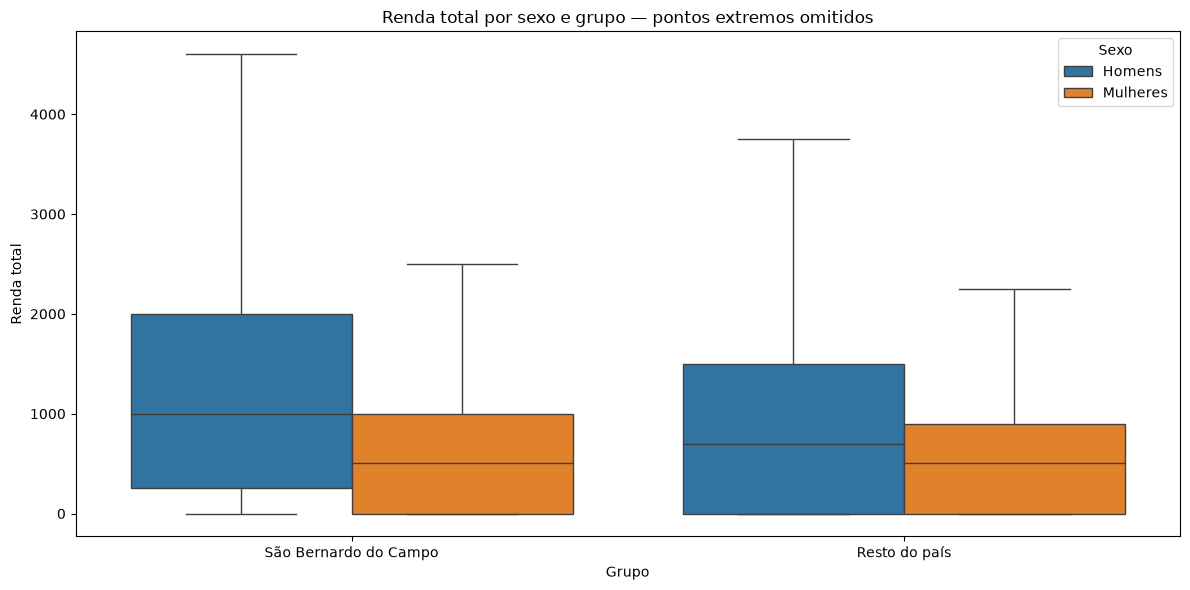


=== TESTE DE MANN–WHITNEY ===
Hipótese alternativa: a renda dos homens tende a ser maior.
Nível de significância: 5% (95% de confiança)

Grupo: São Bernardo do Campo
Amostra de homens: 15555
Amostra de mulheres: 16853
Mediana dos homens: 1000.00
Mediana das mulheres: 510.00
Estatística U: 167609648.00
Valor-p: 0.000e+00
Conclusão: há evidência estatística de que a renda dos homens tende a ser maior.
-------------------------------------------------------
Grupo: Resto do país
Amostra de homens: 1533868
Amostra de mulheres: 1713784
Mediana dos homens: 700.00
Mediana das mulheres: 510.00
Estatística U: 1576352696094.50
Valor-p: 0.000e+00
Conclusão: há evidência estatística de que a renda dos homens tende a ser maior.
-------------------------------------------------------


In [426]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

df_analise = df_comparacao.copy()

# Considerar os códigos do dicionário: 1 = homem, 2 = mulher
df_analise['SEXO'] = (
    df_analise['SEXO'].astype(str).map({
        '1': 'Homens',
        '2': 'Mulheres'
    })
)

# Manter apenas os dados necessários e válidos
df_analise = df_analise.dropna(
    subset=['RENDA_TOTAL', 'SEXO', 'GRUPO']
)

# Conferir os grupos disponíveis
print("Grupos encontrados:", df_analise['GRUPO'].unique())

# Boxplots: comparar homens e mulheres em cada grupo
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_analise,
    x='GRUPO',
    y='RENDA_TOTAL',
    hue='SEXO',
    order=[MUNICIPIO, 'Resto do país'],
    hue_order=['Homens', 'Mulheres'],
    showfliers=False
)

plt.title('Renda total por sexo e grupo — pontos extremos omitidos')
plt.xlabel('Grupo')
plt.ylabel('Renda total')
plt.legend(title='Sexo')
plt.tight_layout()
plt.show()

# Teste de Mann–Whitney unilateral para cada grupo
print("\n=== TESTE DE MANN–WHITNEY ===")
print("Hipótese alternativa: a renda dos homens tende a ser maior.")
print("Nível de significância: 5% (95% de confiança)\n")

for grupo in df_analise['GRUPO'].unique():

    dados = df_analise[df_analise['GRUPO'] == grupo]

    homens = dados.loc[
        dados['SEXO'] == 'Homens', 'RENDA_TOTAL'
    ]

    mulheres = dados.loc[
        dados['SEXO'] == 'Mulheres', 'RENDA_TOTAL'
    ]

    if len(homens) == 0 or len(mulheres) == 0:
        print(f"Grupo: {grupo} — dados insuficientes.")
        continue

    # Teste unilateral: homens > mulheres
    resultado = mannwhitneyu(
        homens,
        mulheres,
        alternative='greater'
    )

    mediana_homens = homens.median()
    mediana_mulheres = mulheres.median()

    print(f"Grupo: {grupo}")
    print(f"Amostra de homens: {len(homens)}")
    print(f"Amostra de mulheres: {len(mulheres)}")
    print(f"Mediana dos homens: {mediana_homens:.2f}")
    print(f"Mediana das mulheres: {mediana_mulheres:.2f}")
    print(f"Estatística U: {resultado.statistic:.2f}")
    print(f"Valor-p: {resultado.pvalue:.3e}")

    if resultado.pvalue < 0.05:
        print(
            "Conclusão: há evidência estatística de que "
            "a renda dos homens tende a ser maior."
        )
    else:
        print(
            "Conclusão: não há evidência estatística "
            "suficiente para afirmar que a renda dos homens "
            "tende a ser maior."
        )

    print("-" * 55)

Os boxplots mostram rendas medianas maiores entre os homens nos dois grupos. Em São Bernardo do Campo, a mediana masculina foi mais de 1000,00 reais enquanto a feminina foi de 510,00 reais. No restante do país, essas medianas foram de 700 reais e 510 reais, respectivamente. O teste de Mann–Whitney unicaudal apresentou valor-p inferior a 0,001 em ambos os grupos. Portanto, ao nível de significância de 5%, há evidência estatística de que os homens tendem a apresentar rendas maiores que as mulheres. Os pontos extremos foram omitidos apenas na visualização, permanecendo nos testes.

<div class="alert alert-primary">
<b>(0,2) 7.1</b> - Explique os resultados obtidos.
</div>


O teste de Mann–Whitney foi aplicado para comparar a distribuição da renda total entre homens e mulheres em São Bernardo do Campo, utilizando um nível de significância de 5%.

Os resultados mostram que a mediana da renda dos homens foi de 1.000,00 reais, enquanto a das mulheres foi de R$ 510,00. Isso indica que a renda central observada entre os homens foi superior à das mulheres na amostra analisada.

O teste apresentou valor-p inferior a 0,05, indicando uma diferença estatisticamente significativa entre as distribuições de renda, com evidências de que a renda dos homens tende a ser maior. Portanto, rejeita-se a hipótese nula em favor da hipótese alternativa.

Conclui-se que, em São Bernardo do Campo, os dados analisados apresentam evidências estatísticas de uma renda total maior entre os homens. Entretanto, esse resultado não demonstra que o sexo seja a causa da diferença observada.

No restante do país, foram analisados 1.533.868 homens e 1.713.784 mulheres. A mediana da renda total foi de  700 reais entre os homens e de R$ 510,00 entre as mulheres.

O teste de Mann–Whitney unicaudal apresentou estatística U de 1.576.352.696.094,50 e valor-p inferior a 0,001. Portanto, ao nível de significância de 5%, há evidência estatística de que os homens tendem a apresentar rendas maiores que as mulheres no restante do país.

<div class="alert alert-info">
<b>(0,4) 8</b> - Compare a distribuição de <code>RENDA_TOTAL</code> por cor/raça (<code>COR_RACA</code>), tanto no seu município quanto no resto do país. Use um gráfico de violino e um gráfico de barras com intervalo de confiança. Qual a melhor visualização e porque?
</div>


GRUPO,Resto do país,São Bernardo do Campo
COR_RACA,,
Amarela,42544,637
Branca,1551473,20204
Indígena,6331,42
Parda,1297479,9159
Preta,283760,1705


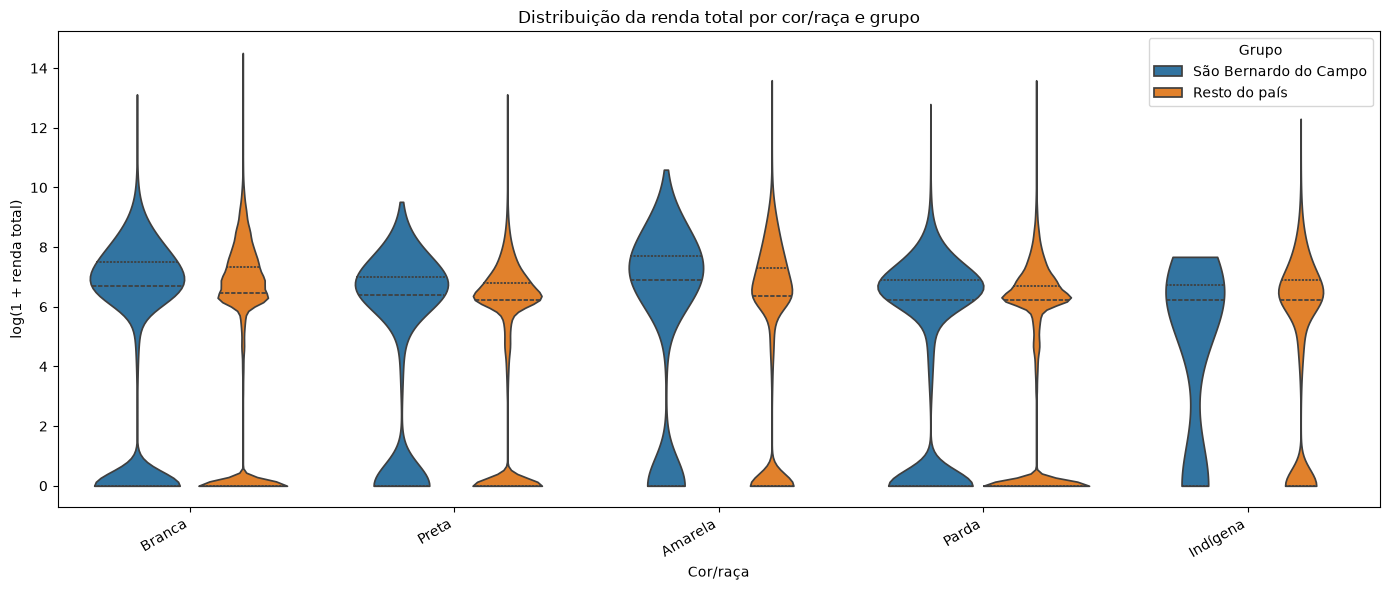

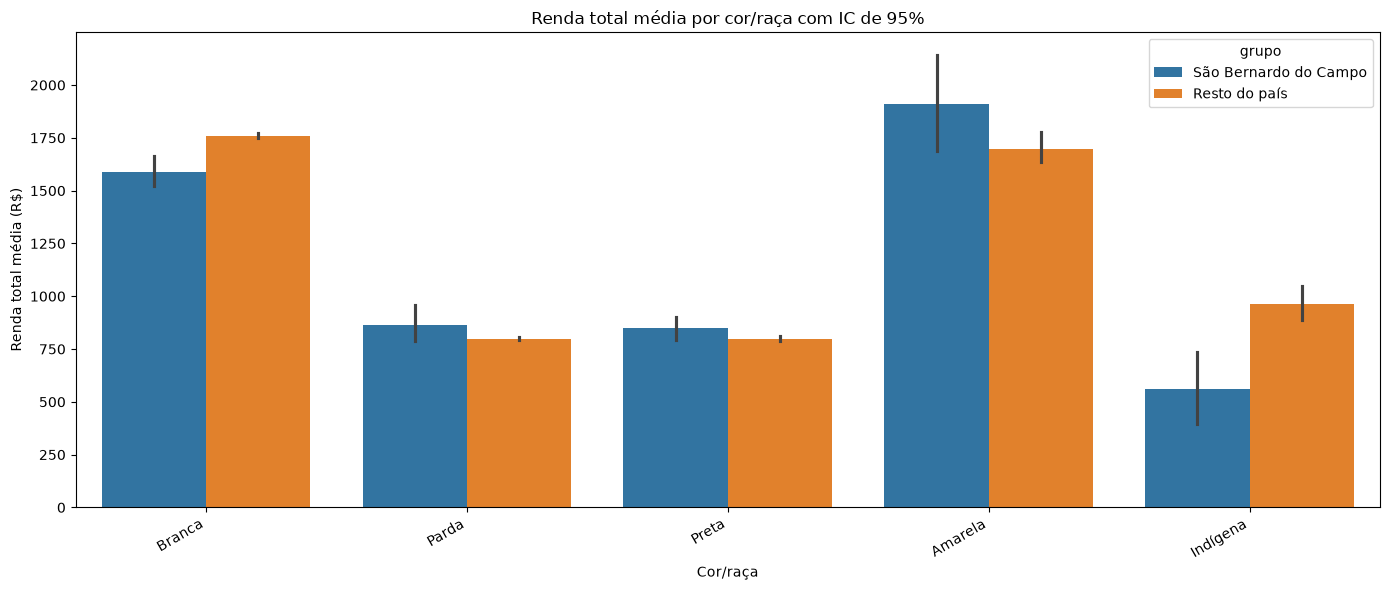

In [427]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dados de São Bernardo do Campo
df_municipio_q8 = df_censo[
    ["RENDA_TOTAL", "COR_RACA"]
].copy()

df_municipio_q8["GRUPO"] = MUNICIPIO

# Usar os dados do restante do país preparados na questão 7.
df_resto_q8 = df_resto[
    ["RENDA_TOTAL", "COR_RACA"]
].copy()

df_resto_q8["GRUPO"] = "Resto do país"

# Reunir os dois grupos.
df_grafico = pd.concat(
    [df_municipio_q8, df_resto_q8],
    ignore_index=True
)

# Converter os códigos para os nomes do dicionário.
nomes_raca = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indígena"
}

df_grafico["COR_RACA"] = (
    df_grafico["COR_RACA"].astype(str).map(nomes_raca)
)

# Excluir da comparação os registros sem cor/raça identificada.
# Isso inclui "Não informado" e o código 9 ("Ignorado").
df_grafico = df_grafico.dropna(
    subset=["RENDA_TOTAL", "COR_RACA", "GRUPO"]
).copy()

ordem_raca = ["Branca", "Preta", "Amarela", "Parda", "Indígena"]
ordem_grupo = [MUNICIPIO, "Resto do país"]

# Transformação apenas para visualizar melhor o violino.
# log1p mantém as rendas iguais a zero: log(1 + 0) = 0.
df_grafico["RENDA_LOG"] = np.log1p(df_grafico["RENDA_TOTAL"])

# Conferir a quantidade de registros por categoria e grupo.
display(pd.crosstab(df_grafico["COR_RACA"], df_grafico["GRUPO"]))

# Gráfico 1: violino.
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=df_grafico,
    x="COR_RACA",
    y="RENDA_LOG",
    hue="GRUPO",
    order=ordem_raca,
    hue_order=ordem_grupo,
    split=False,
    cut=0,
    inner="quartile"
)

plt.title("Distribuição da renda total por cor/raça e grupo")
plt.xlabel("Cor/raça")
plt.ylabel("log(1 + renda total)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()

# Gráfico 2: barras com intervalo de confiança de 95%
plt.figure(figsize=(14, 6))

sns.barplot(
    data=df_grafico,
    x='COR_RACA',
    y='RENDA_TOTAL',
    hue='GRUPO',
    errorbar=("ci", 95),
    seed=42
)

plt.title('Renda total média por cor/raça com IC de 95%')
plt.xlabel('Cor/raça')
plt.ylabel('Renda total média (R$)')
plt.xticks(rotation=30, ha='right')
plt.legend(title='grupo')
plt.tight_layout()
plt.show()


### Análise da renda total por cor/raça

Foram comparadas as distribuições de renda total das categorias Branca, Preta, Amarela, Parda e Indígena em São Bernardo do Campo e no restante do país. Registros sem identificação de cor/raça, incluindo o código “Ignorado”, foram excluídos desta comparação.

O gráfico de violino utiliza a transformação log(1 + RENDA_TOTAL), que facilita visualizar a distribuição sem excluir rendas muito altas ou iguais a zero. Seu eixo vertical não representa diretamente valores em reais. Observam-se concentrações em renda zero e diferenças na distribuição entre as categorias e os dois grupos.

O gráfico de barras apresenta as rendas médias em reais, acompanhadas de intervalos de confiança de 95%. Em São Bernardo do Campo, a categoria Amarela apresenta a maior média, seguida da Branca. No restante do país, a categoria Branca apresenta a maior média, seguida da Amarela. As médias das categorias Preta e Parda são próximas entre si nos dois grupos. A média da categoria Indígena é menor no município do que no restante do país.

As comparações envolvendo a categoria Indígena no município exigem cautela, pois ela possui somente 42 registros. Os intervalos de confiança representam a incerteza das médias estimadas, e não a faixa que contém 95% das rendas individuais.

### Qual visualização é mais adequada?

Para o objetivo de comparar distribuições, o gráfico de violino é mais adequado, pois mostra a concentração, a dispersão e a assimetria dos valores, além da presença de rendas iguais a zero. A transformação logarítmica tornou essas características mais visíveis.

O gráfico de barras complementa a análise ao facilitar a comparação das médias e de sua incerteza. Entretanto, ele não mostra como as rendas se distribuem dentro de cada categoria, e suas médias podem ser influenciadas por valores muito altos.

<div class="alert alert-primary">
<b>(0,25) 8.1</b> - Explique os resultados obtidos.
</div>


Em São Bernardo do Campo, a categoria Amarela apresenta a maior renda total média, seguida da Branca. No restante do país, essa ordem se inverte: a categoria Branca apresenta a maior média, seguida da Amarela. As categorias Preta e Parda possuem médias próximas entre si nos dois grupos.

Comparando cada categoria entre o município e o restante do país, as médias municipais são maiores nas categorias Amarela, Preta e Parda, enquanto as médias do restante do país são maiores nas categorias Branca e Indígena. Essas diferenças são descritivas; os gráficos, isoladamente, não comprovam significância estatística em todas as comparações.

Os violinos mostram concentrações em renda zero e caudas que se estendem para rendas mais altas, indicando assimetria e variação dentro das categorias. A transformação log(1 + RENDA_TOTAL) facilita visualizar essas características sem excluir registros.

Os intervalos de confiança de 95% indicam a incerteza das médias estimadas. A categoria Indígena em São Bernardo do Campo possui somente 42 registros e apresenta maior incerteza relativa, exigindo cautela na interpretação. As categorias “Ignorado” e “Não informado” foram excluídas desta análise por não identificarem uma cor/raça.

<div class="alert alert-info">
<b>(0,35) 9</b> - Trace a renda média por faixa etária (crie faixas de 10 em 10 anos, aproximadamente) tanto para o seu município quanto para o resto do país, usando um gráfico de linhas com intervalo de confiança (95%). Isso corresponde ao "ciclo de vida" da renda de uma pessoa. As diferenças de renda média entre faixas etárias vizinhas são estatisticamente significativas em toda a curva ou o tamanho da amostra é pequeno demais para sustentar essa leitura em algum trecho?
</div>


TABELA 1 — RENDA MÉDIA POR FAIXA ETÁRIA E GRUPO
                GRUPO FAIXA_ETARIA        n   media  mediana  IC95_inferior  IC95_superior
        Resto do país        10-19 625121.0  117.52      0.0         113.74         121.31
        Resto do país        20-29 704870.0  842.03    510.0         835.37         848.69
        Resto do país        30-39 617909.0 1482.49    715.0        1470.46        1494.52
        Resto do país        40-49 510603.0 1786.21    800.0        1770.18        1802.24
        Resto do país        50-59 383199.0 2118.68    800.0        2088.87        2148.49
        Resto do país        60-69 224099.0 2202.64    750.0        2150.31        2254.97
        Resto do país        70-79 123334.0 1988.50    593.5        1933.60        2043.40
        Resto do país        80-89  50125.0 2024.02    510.0        1908.92        2139.11
        Resto do país        90-99   8011.0 1685.16    510.0        1488.00        1882.31
        Resto do país         100+    381.

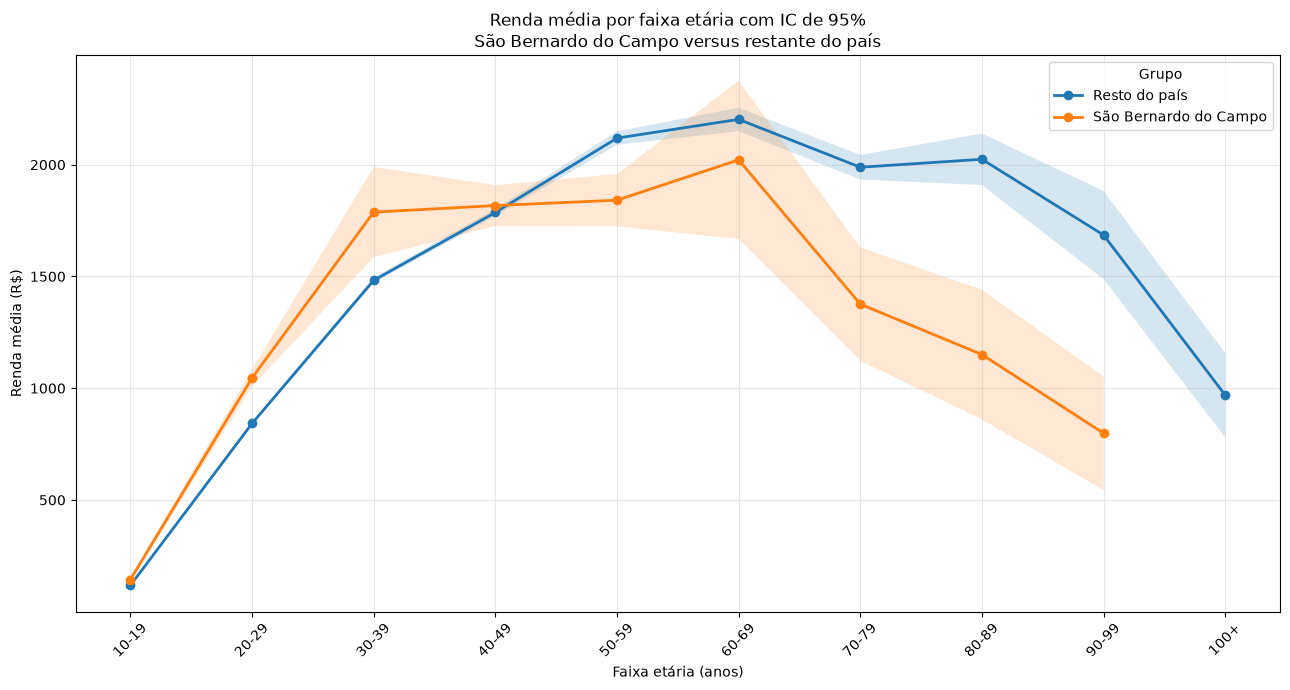


TABELA 2 — COMPARAÇÃO ENTRE FAIXAS VIZINHAS

Grupo: São Bernardo do Campo
                GRUPO     Comparacao  n_faixa_a  n_faixa_b  diferenca_media  p_valor  p_ajustado_Holm  Significativo_5%         Resultado  Amostra_pequena
São Bernardo do Campo 10-19 vs 20-29       5722       6982         902.3911   0.0000           0.0000              True     Significativa            False
São Bernardo do Campo 20-29 vs 30-39       6982       6384         741.7645   0.0000           0.0000              True     Significativa            False
São Bernardo do Campo 30-39 vs 40-49       6384       5374          29.3364   0.7954           1.0000             False Não significativa            False
São Bernardo do Campo 40-49 vs 50-59       5374       4170          24.2069   0.7493           1.0000             False Não significativa            False
São Bernardo do Campo 50-59 vs 60-69       4170       2263         180.2874   0.3437           1.0000             False Não significativa            F

In [428]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Reunir município e restante do país, já tratados.
df_municipio_q9 = df_censo[["IDADE", "RENDA_TOTAL"]].copy()
df_municipio_q9["GRUPO"] = MUNICIPIO

df_resto_q9 = df_resto[["IDADE", "RENDA_TOTAL"]].copy()
df_resto_q9["GRUPO"] = "Resto do país"

df_idade = pd.concat(
    [df_municipio_q9, df_resto_q9],
    ignore_index=True
)
df_idade['IDADE'] = pd.to_numeric(
    df_idade['IDADE'], errors='coerce'
)
df_idade['RENDA_TOTAL'] = pd.to_numeric(
    df_idade['RENDA_TOTAL'], errors='coerce'
)

# Manter a faixa etária de 10 a 140 anos
df_idade = df_idade.dropna(
    subset=['IDADE', 'RENDA_TOTAL', 'GRUPO']
).copy()

df_idade = df_idade[
    df_idade["IDADE"].between(10, 140)
].copy()

# Criar faixas de aproximadamente 10 anos.
rotulos = [
    f"{i}-{i+9}" for i in range(10, 100, 10)
] + ["100+"]

df_idade["FAIXA_ETARIA"] = pd.cut(
    df_idade["IDADE"],
    bins=list(range(10, 101, 10)) + [float("inf")],
    labels=rotulos,
    right=False
)

# ============================================================
# 2. CALCULAR MÉDIAS E INTERVALOS DE CONFIANÇA DE 95%
# ============================================================

def calcular_resumo(grupo):
    renda = grupo['RENDA_TOTAL'].dropna()
    n = len(renda)
    media = renda.mean()

    if n >= 2:
        margem = stats.t.ppf(0.975, n - 1) * stats.sem(renda)
        inferior = media - margem
        superior = media + margem
    else:
        inferior = np.nan
        superior = np.nan

    return pd.Series({
        'n': n,
        'media': media,
        'mediana': renda.median(),
        'IC95_inferior': inferior,
        'IC95_superior': superior
    })

resumo = (
    df_idade
    .groupby(['GRUPO', 'FAIXA_ETARIA'], observed=False)
    .apply(calcular_resumo)
    .reset_index()
)

print("=" * 75)
print("TABELA 1 — RENDA MÉDIA POR FAIXA ETÁRIA E GRUPO")
print("=" * 75)
print(resumo.round(2).to_string(index=False))

# ============================================================
# 3. GRÁFICO DE LINHAS COM INTERVALO DE CONFIANÇA DE 95%
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))

for grupo in resumo['GRUPO'].dropna().unique():
    dados = resumo[resumo['GRUPO'] == grupo].copy()
    dados = dados.loc[dados["n"] >= 2].copy()

    # Posicionar cada faixa etária no eixo correto
    x = np.array([
        rotulos.index(str(faixa))
        for faixa in dados['FAIXA_ETARIA']
    ])

    medias = dados['media'].to_numpy()
    inferiores = dados['IC95_inferior'].to_numpy()
    superiores = dados['IC95_superior'].to_numpy()

    ax.plot(
        x, medias,
        marker='o',
        linewidth=2,
        label=str(grupo)
    )

    ax.fill_between(
        x, inferiores, superiores,
        alpha=0.18
    )

ax.set_xticks(range(len(rotulos)))
ax.set_xticklabels(rotulos, rotation=45)
ax.set_xlabel('Faixa etária (anos)')
ax.set_ylabel('Renda média (R$)')
ax.set_title(
    "Renda média por faixa etária com IC de 95%\n"
    "São Bernardo do Campo versus restante do país"
)
ax.legend(title='Grupo')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 4. TESTAR DIFERENÇAS ENTRE FAIXAS ETÁRIAS VIZINHAS
#    Teste t de Welch + correção de Holm
# ============================================================

def ajustar_holm(p_valores):
    """Corrige os valores-p válidos pelo método de Holm."""
    p_valores = np.asarray(p_valores, dtype=float)
    ajustados = np.full(len(p_valores), np.nan)

    validos = np.isfinite(p_valores)

    if not validos.any():
        return ajustados

    p = p_valores[validos]
    m = len(p)
    ordem = np.argsort(p)
    ordenados = p[ordem]

    ajustados_ordem = np.maximum.accumulate(
        np.minimum(1, (m - np.arange(m)) * ordenados)
    )

    resultado = np.empty(m)
    resultado[ordem] = ajustados_ordem
    ajustados[validos] = resultado

    return ajustados


print("\n" + "=" * 75)
print("TABELA 2 — COMPARAÇÃO ENTRE FAIXAS VIZINHAS")
print("=" * 75)

todas_comparacoes = []

for grupo in df_idade['GRUPO'].dropna().unique():
    dados_grupo = df_idade[df_idade['GRUPO'] == grupo]
    resultados = []

    for i in range(len(rotulos) - 1):
        faixa_a = rotulos[i]
        faixa_b = rotulos[i + 1]

        a = dados_grupo.loc[
            dados_grupo['FAIXA_ETARIA'] == faixa_a,
            'RENDA_TOTAL'
        ].dropna()

        b = dados_grupo.loc[
            dados_grupo['FAIXA_ETARIA'] == faixa_b,
            'RENDA_TOTAL'
        ].dropna()

        if len(a) >= 2 and len(b) >= 2:
            teste = stats.ttest_ind(
                a, b,
                equal_var=False,
                alternative='two-sided'
            )
            p = teste.pvalue
            diferenca = b.mean() - a.mean()
        else:
            p = np.nan
            diferenca = np.nan

        resultados.append({
            'GRUPO': grupo,
            'Comparacao': f'{faixa_a} vs {faixa_b}',
            'n_faixa_a': len(a),
            'n_faixa_b': len(b),
            'diferenca_media': diferenca,
            'p_valor': p
        })

    tabela = pd.DataFrame(resultados)

    # Corrigir comparações múltiplas separadamente em cada grupo
    tabela['p_ajustado_Holm'] = ajustar_holm(
        tabela['p_valor'].to_numpy()
    )

    tabela['Significativo_5%'] = (
        tabela['p_ajustado_Holm'] < 0.05
    )

    tabela["Resultado"] = np.where(
    tabela["p_ajustado_Holm"].isna(),
    "Não avaliável",
    np.where(
        tabela["Significativo_5%"],
        "Significativa",
        "Não significativa"
        )
    )

    tabela['Amostra_pequena'] = (
        (tabela['n_faixa_a'] < 30) |
        (tabela['n_faixa_b'] < 30)
    )

    print(f"\nGrupo: {grupo}")
    print(tabela.round(4).to_string(index=False))

    todas_comparacoes.append(tabela)

# ============================================================
# 5. RESUMO DAS COMPARAÇÕES ESTATÍSTICAS
# ============================================================

if todas_comparacoes:
    comparacoes = pd.concat(
        todas_comparacoes, ignore_index=True
    )

    print("\n" + "=" * 75)
    print("TABELA 3 — RESUMO DOS TESTES")
    print("=" * 75)

    for grupo, dados in comparacoes.groupby('GRUPO'):
        total = dados['p_ajustado_Holm'].notna().sum()
        significativas = dados['Significativo_5%'].sum()
        pequenas = dados['Amostra_pequena'].sum()

        print(f"\nGrupo: {grupo}")
        print(f"Comparações avaliáveis: {total}")
        print(f"Diferenças significativas após ajuste: {significativas}")
        print(f"Comparações com alguma faixa contendo menos de 30 pessoas: {pequenas}")

print("\nAnálise concluída.")

<div class="alert alert-primary">
<b>(0,3) 9.1</b> - Explique os resultados obtidos.
</div>


A renda média apresenta um padrão de crescimento entre as faixas mais jovens e as faixas de idade intermediária, seguido de redução nas idades mais avançadas. Nos dois grupos, a maior média observada ocorre entre 60 e 69 anos: 2.021,43 reais em São Bernardo do Campo e 2.202,64 reais no restante do país. Entretanto, a curva compara pessoas de diferentes idades no Censo de 2010; ela não acompanha a trajetória de renda de uma mesma pessoa durante sua vida.

Para avaliar as diferenças entre faixas vizinhas, foi aplicado o teste t de Welch, com correção de Holm para comparações múltiplas e nível de significância de 5%. Em São Bernardo do Campo, 3 das 8 comparações avaliáveis foram significativas: 10–19 versus 20–29, 20–29 versus 30–39 e 60–69 versus 70–79. No restante do país, 8 das 9 comparações foram significativas; a única exceção foi 70–79 versus 80–89. Assim, as diferenças não são estatisticamente significativas em toda a curva.

Os intervalos de confiança de 95% mostram a incerteza das médias estimadas. No município, a faixa de 100 anos ou mais possui apenas uma pessoa, impossibilitando calcular seu intervalo de confiança e testar sua diferença em relação à faixa anterior. Por esse motivo, ela foi mantida na tabela, mas omitida da curva municipal.

A ausência de significância nas demais comparações não comprova igualdade entre as médias nem pode ser atribuída automaticamente a uma amostra pequena. A variabilidade das rendas, a magnitude das diferenças e o ajuste para comparações múltiplas também influenciam os resultados.

<div class="alert alert-info">
<b>(0,35) 10</b> - Qual a relação entre o nível de instrução (<code>NIVEL_INSTRUCAO</code>) e a renda, tanto no seu município quanto no resto do país? Mostre uma tabela dinâmica (pivot table) com a renda média por nível de instrução e grupo, e calcule a correlação de Spearman entre nível de instrução (tratado como ordinal) e renda em cada grupo.
</div>


In [429]:

from scipy.stats import spearmanr
import pandas as pd

df_municipio_q10 = df_censo[
    ["NIVEL_INSTRUCAO", "RENDA_TOTAL"]
].copy()
df_municipio_q10["GRUPO"] = MUNICIPIO

# Usar o restante do país já tratado na questão 7.
df_resto_q10 = df_resto[
    ["NIVEL_INSTRUCAO", "RENDA_TOTAL"]
].copy()
df_resto_q10["GRUPO"] = "Resto do país"

# Reunir os dois grupos.
df_instrucao = pd.concat(
    [df_municipio_q10, df_resto_q10],
    ignore_index=True
)

df_instrucao["NIVEL_INSTRUCAO"] = pd.to_numeric(
    df_instrucao["NIVEL_INSTRUCAO"], errors="coerce"
)
df_instrucao["RENDA_TOTAL"] = pd.to_numeric(
    df_instrucao["RENDA_TOTAL"], errors="coerce"
)

df_instrucao = df_instrucao.dropna(
    subset=["NIVEL_INSTRUCAO", "RENDA_TOTAL", "GRUPO"]
)

# Manter somente os níveis com ordem de escolaridade definida.
df_instrucao = df_instrucao[
    df_instrucao["NIVEL_INSTRUCAO"].isin([1, 2, 3, 4])
].copy()

nomes_instrucao = {
    1: "Sem instrução e fundamental incompleto",
    2: "Fundamental completo e médio incompleto",
    3: "Médio completo e superior incompleto",
    4: "Superior completo"
}

# Tabela dinâmica: renda média por nível e grupo.
tabela_media = df_instrucao.pivot_table(
    index="NIVEL_INSTRUCAO",
    columns="GRUPO",
    values="RENDA_TOTAL",
    aggfunc="mean"
)

tabela_media = tabela_media.reindex(
    index=[1, 2, 3, 4],
    columns=[MUNICIPIO, "Resto do país"]
)

tabela_media = tabela_media.rename(index=nomes_instrucao)

print("RENDA TOTAL MÉDIA POR NÍVEL DE INSTRUÇÃO (R$)")
display(tabela_media.round(2))

resultados = []

for grupo, dados in df_instrucao.groupby("GRUPO"):
    rho, p_valor = spearmanr(
        dados["NIVEL_INSTRUCAO"],
        dados["RENDA_TOTAL"]
    )

    resultados.append({
        "GRUPO": grupo,
        "N": len(dados),
        "CORRELACAO_SPEARMAN": rho,
        "P_VALOR": p_valor
    })

tabela_spearman = pd.DataFrame(resultados)

print("CORRELAÇÃO DE SPEARMAN POR GRUPO")

display(
    tabela_spearman.style.format({
        "N": "{:.0f}",
        "CORRELACAO_SPEARMAN": "{:.4f}",
        "P_VALOR": lambda p: "< 0,001" if p < 0.001 else f"{p:.4f}"
    })
)

RENDA TOTAL MÉDIA POR NÍVEL DE INSTRUÇÃO (R$)


GRUPO,São Bernardo do Campo,Resto do país
NIVEL_INSTRUCAO,,
Sem instrução e fundamental incompleto,756.37,527.19
Fundamental completo e médio incompleto,810.87,717.31
Médio completo e superior incompleto,1325.80,1245.77
Superior completo,3465.96,4540.56


CORRELAÇÃO DE SPEARMAN POR GRUPO


,GRUPO,N,CORRELACAO_SPEARMAN,P_VALOR
0,Resto do país,3159557,0.4233,"< 0,001"
1,São Bernardo do Campo,31498,0.4288,"< 0,001"


<div class="alert alert-primary">
<b>(0,2) 10.1</b> - Explique os resultados obtidos.
</div>


A tabela dinâmica mostra que a renda média aumenta conforme o nível de instrução, tanto em São Bernardo do Campo quanto no restante do país. No município, a média passa de 756,37 reais entre pessoas sem instrução ou com ensino fundamental incompleto para 3.465,96 reais entre aquelas com ensino superior completo. No restante do país, os valores correspondentes são 527,19 reais e 4.540,56 reais.

São Bernardo do Campo apresenta renda média superior à do restante do país nos três primeiros níveis de instrução. Entretanto, entre pessoas com ensino superior completo, a renda média é maior no restante do país.

A correlação de Spearman foi de aproximadamente 0,4288 no município e 0,4233 no restante do país, indicando uma associação positiva de magnitude moderada e semelhante nos dois recortes: níveis mais elevados de instrução tendem a estar associados a rendas maiores. Os valores-p foram inferiores a 0,001, indicando significância estatística ao nível de 5%. A exibição de zero na saída numérica não significa que a probabilidade seja exatamente zero.

Foram analisados 31.498 registros do município e 3.159.557 do restante do país, considerando apenas os quatro níveis de instrução com ordem definida e registros com renda válida. Categorias ausentes ou de instrução não determinada foram excluídas.

Esses resultados demonstram associação, mas não permitem concluir que a escolaridade, isoladamente, cause o aumento da renda. Outros fatores, como idade, experiência profissional e ocupação, também podem estar relacionados às diferenças observadas.

A tabela dinâmica mostra que a renda total média aumenta conforme o nível de instrução nos dois grupos. Em São Bernardo do Campo, ela passa de 756,37 reais entre pessoas sem instrução ou com ensino fundamental incompleto para 3.465,96 reais entre pessoas com ensino superior completo. No restante do país, esses valores são de 527,19 reais e 4.540,56 reais, respectivamente.

Nas três primeiras categorias de instrução, o município apresenta médias maiores que o restante do país. Entre pessoas com ensino superior completo, essa relação se inverte: a média é maior no restante do país.

A correlação de Spearman foi de 0,4288 em São Bernardo do Campo e de 0,4233 no restante do país, com valor-p inferior a 0,001 em ambos. Os resultados indicam uma associação positiva de magnitude semelhante nos dois grupos: níveis mais altos de instrução tendem a estar associados a rendas maiores.

Foram analisados 31.498 registros no município e 3.159.557 no restante do país. Os casos sem informação de escolaridade e a categoria “Não determinado” foram excluídos, pois não podem ser posicionados na ordem dos níveis de instrução.

Essa associação não demonstra que a escolaridade, isoladamente, cause o aumento da renda. Outros fatores, como idade, ocupação e experiência profissional, também podem estar relacionados aos rendimentos.

<div class="alert alert-info">
<b>(0,3) 11</b> - Qual a renda média de acordo com a posição na ocupação (<code>POSICAO_OCUPACAO</code>), tanto no seu município quanto no resto do país?
</div>


In [430]:

import pandas as pd

df_municipio_q11 = df_censo[
    ["POSICAO_OCUPACAO", "RENDA_TOTAL"]
].copy()

df_municipio_q11["GRUPO"] = MUNICIPIO

# Usar o restante do país já tratado na questão 7.
df_resto_q11 = df_resto[
    ["POSICAO_OCUPACAO", "RENDA_TOTAL"]
].copy()

df_resto_q11["GRUPO"] = "Resto do país"

# Reunir os dois grupos.
df_ocupacao = pd.concat(
    [df_municipio_q11, df_resto_q11],
    ignore_index=True
)

# Garantir que a renda seja numérica
df_ocupacao["RENDA_TOTAL"] = pd.to_numeric(
    df_ocupacao["RENDA_TOTAL"], errors="coerce"
)

# Remover registros sem posição na ocupação, renda ou grupo
df_ocupacao = df_ocupacao.dropna(
    subset=["POSICAO_OCUPACAO", "RENDA_TOTAL", "GRUPO"]
)

# Calcular a renda média por posição na ocupação e grupo
tabela_renda_ocupacao = pd.pivot_table(
    df_ocupacao,
    values="RENDA_TOTAL",
    index="POSICAO_OCUPACAO",
    columns="GRUPO",
    aggfunc="mean"
)

print("Renda média por posição na ocupação:")
display(tabela_renda_ocupacao.round(2))

# Quantidade de registros em cada categoria
print("Quantidade de registros por posição e grupo:")
display(
    pd.pivot_table(
        df_ocupacao,
        values="RENDA_TOTAL",
        index="POSICAO_OCUPACAO",
        columns="GRUPO",
        aggfunc="count",
        fill_value=0
    )
)

Renda média por posição na ocupação:


GRUPO,Resto do país,São Bernardo do Campo
POSICAO_OCUPACAO,,
1,1734.79,1908.31
2,4185.71,2693.21
3,1004.76,1217.69
4,2113.49,2447.80
5,7482.46,9432.03
6,362.90,275.51
7,362.05,206.55


Quantidade de registros por posição e grupo:


GRUPO,Resto do país,São Bernardo do Campo
POSICAO_OCUPACAO,,
1,941687,11637
2,108357,523
3,298093,2607
4,357090,3038
5,41107,432
6,21327,200
7,10279,22


<div class="alert alert-primary">
<b>(0,2) 11.1</b> - Explique os resultados obtidos.
</div>


A renda total média varia entre as posições na ocupação nos dois grupos. A categoria 5 apresenta a maior média: 9.432,03 reais em São Bernardo do Campo e R$ 7.482,46 no restante do país. Em ambos os grupos, ela é seguida pelas categorias 2 e 4.

O município apresenta médias maiores que o restante do país nas categorias 1, 3, 4 e 5. Nas categorias 2, 6 e 7, ocorre o contrário. A categoria 2 apresenta uma diferença expressiva: 2.693,21 reais no município e R$ 4.185,71 no restante do país.

As menores médias estão nas categorias 6 e 7. Em São Bernardo do Campo, elas correspondem a 275,51 reais e 206,55 reais, respectivamente; no restante do país, a 362,90 reais e 362,05 reais. Como a variável analisada é RENDA_TOTAL, os valores podem incluir outras fontes de rendimento, além do trabalho.

A tabela de quantidades ajuda a contextualizar os resultados. A categoria 7 possui somente 22 registros no município, portanto sua média exige cautela. Além disso, médias podem ser influenciadas por rendas muito altas. As diferenças apresentadas são descritivas: não foi aplicado um teste para avaliar sua significância estatística.

Foram considerados somente registros com posição na ocupação e renda total informadas. Assim, os resultados descrevem esse subconjunto dos dados, e não toda a população dos dois grupos.

<div class="alert alert-info">
<b>(0,35) 12</b> - Combine cor/raça e sexo em uma única tabela dinâmica de renda média, considerando apenas o seu município. O que se observa sobre desigualdade "interseccional" (por raça e por gênero simultaneamente)?
</div>


In [431]:
import pandas as pd

df_interseccional = df_censo.copy()

# Garantir que a renda seja numérica
df_interseccional["RENDA_TOTAL"] = pd.to_numeric(
    df_interseccional["RENDA_TOTAL"], errors="coerce"
)

# Filtrar somente o município solicitado.
df_interseccional = df_interseccional[
    (df_interseccional["NOME_MUNICIPIO"] == MUNICIPIO)
    & (df_interseccional["SIGLA_UF"] == SIGLA_UF)
].copy()

# Identificar as cinco categorias de cor/raça.
nomes_raca = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indígena"
}

df_interseccional["COR_RACA"] = (
    df_interseccional["COR_RACA"].astype(str).map(nomes_raca)
)

# Identificar os sexos.
df_interseccional["SEXO"] = (
    df_interseccional["SEXO"].astype(str).map({
        "1": "Homens",
        "2": "Mulheres"
    })
)

# Remover registros sem informação de raça, sexo ou renda
df_interseccional = df_interseccional.dropna(
    subset=["COR_RACA", "SEXO", "RENDA_TOTAL"]
)

# Tabela dinâmica: cor/raça nas linhas e sexo nas colunas
tabela_interseccional = pd.pivot_table(
    df_interseccional,
    values="RENDA_TOTAL",
    index="COR_RACA",
    columns="SEXO",
    aggfunc="mean"
)

print("Renda média por cor/raça e sexo — São Bernardo do Campo:")
display(tabela_interseccional.round(2))

# Quantidade de pessoas em cada combinação
tabela_quantidade = pd.pivot_table(
    df_interseccional,
    values="RENDA_TOTAL",
    index="COR_RACA",
    columns="SEXO",
    aggfunc="count",
    fill_value=0
)

print("Quantidade de registros por combinação:")
display(tabela_quantidade)

Renda média por cor/raça e sexo — São Bernardo do Campo:


SEXO,Homens,Mulheres
COR_RACA,,
Amarela,2689.96,1248.53
Branca,2168.72,1071.66
Indígena,746.43,468.93
Parda,1152.32,576.14
Preta,1078.78,590.48


Quantidade de registros por combinação:


SEXO,Homens,Mulheres
COR_RACA,,
Amarela,293,344
Branca,9480,10724
Indígena,14,28
Parda,4563,4596
Preta,897,808


<div class="alert alert-primary">
<b>(0,25) 12.1</b> - Explique os resultados obtidos.
</div>


A tabela de São Bernardo do Campo mostra diferenças de renda média por raça e gênero simultaneamente. Em todas as categorias de cor/raça, os homens apresentam renda média superior à das mulheres. Na categoria Branca, por exemplo, a média masculina é de 2.168,72 reais, enquanto a feminina é de R$ 1.071,66.

Também existem diferenças raciais dentro de cada sexo. Entre as mulheres, a renda média é de 1.248,53 reais na categoria Amarela e de 1.071,66 reais na Branca, enquanto nas categorias Preta, Parda e Indígena corresponde a 590,48 reais, 576,14 reais e R$ 468,93, respectivamente. Entre os homens, as maiores médias também aparecem nas categorias Amarela e Branca.

Esses resultados ilustram a desigualdade interseccional: observar somente raça ou somente gênero pode esconder diferenças entre suas combinações. Por exemplo, mulheres pretas e pardas apresentam renda média inferior tanto à dos homens da mesma categoria racial quanto à das mulheres brancas.

A interpretação exige cautela, especialmente na categoria Indígena, que possui apenas 14 homens e 28 mulheres. Além disso, as médias podem ser influenciadas por rendas muito altas. A análise é descritiva e não comprova as causas das diferenças nem sua significância estatística. Os registros sem identificação de cor/raça foram excluídos desta comparação.

---

#### Transformação e engenharia de atributos


<div class="alert alert-info">
<b>(0,25) 13</b> - Examine a cardinalidade (número de valores distintos) de <code>COD_OCUPACAO</code> e <code>COD_ATIVIDADE_ECON</code>, comparando com a de outras variáveis categóricas da base (ex.: <code>POSICAO_OCUPACAO</code>, <code>SUBGRUPO_OCUPACAO</code>, <code>NIVEL_INSTRUCAO</code>, <code>COR_RACA</code>).
</div>


In [432]:

import pandas as pd

# Variáveis que serão comparadas
colunas = [
    "COD_OCUPACAO",
    "COD_ATIVIDADE_ECON",
    "POSICAO_OCUPACAO",
    "SUBGRUPO_OCUPACAO",
    "NIVEL_INSTRUCAO",
    "COR_RACA",
    "SEXO"
]

resultados = []

for coluna in colunas:
    if coluna in df_censo.columns:
        resultados.append({
            "Variável": coluna,
            "Valores distintos": df_censo[coluna].nunique(),
            "Valores ausentes": df_censo[coluna].isna().sum()
        })
    else:
        print(f"A coluna {coluna} não foi encontrada na base.")

# Organizar do maior para o menor número de valores distintos
tabela_cardinalidade = pd.DataFrame(resultados)

tabela_cardinalidade = tabela_cardinalidade.sort_values(
    by="Valores distintos",
    ascending=False
)

display(tabela_cardinalidade)

,Variável,Valores distintos,Valores ausentes
0,COD_OCUPACAO,357,13949
1,COD_ATIVIDADE_ECON,202,13949
2,POSICAO_OCUPACAO,7,13949
5,COR_RACA,7,0
4,NIVEL_INSTRUCAO,6,0
3,SUBGRUPO_OCUPACAO,5,17641
6,SEXO,2,0


<div class="alert alert-primary">
<b>(0,25) 13.1</b> - O que essa cardinalidade implica para o uso de <code>COD_OCUPACAO</code> e <code>COD_ATIVIDADE_ECON</code> como atributos preditivos (ex.: ao aplicar one-hot encoding)? Cite ao menos uma estratégia de codificação alternativa que poderia mitigar o problema, caso decidam usar essas variáveis no TP2.
</div>


A alta cardinalidade de `COD_OCUPACAO` (357 valores distintos) e `COD_ATIVIDADE_ECON` (202 valores distintos) pode dificultar seu uso como atributos preditivos em modelos de aprendizado de máquina. Ao aplicar **one-hot encoding**, seria criada uma coluna para cada categoria, aumentando a dimensionalidade dos dados e o consumo de memória. Além disso, categorias com poucas observações podem dificultar o aprendizado do modelo e favorecer o sobreajuste (_overfitting_).

Uma alternativa é utilizar **target encoding**, que substitui cada categoria por uma estatística relacionada à variável que se deseja prever, como a média do valor-alvo. Essa técnica deve ser aplicada com validação adequada para evitar vazamento de dados (_data leakage_). Outra possibilidade é agrupar categorias pouco frequentes em uma categoria denominada “Outros” ou utilizar **frequency encoding**, que representa cada categoria pela frequência com que aparece na base.

Portanto, para o TP2, a escolha da codificação deve considerar o modelo utilizado, a frequência das categorias e o tamanho da base, buscando reduzir a dimensionalidade sem perder informações relevantes para a previsão.


<div class="alert alert-info">
<b>(0,3) 14</b> - A partir de <code>IDADE</code>, crie a coluna <code>FAIXA_ETARIA</code> com os seguintes intervalos (mantenha esse nome de coluna e esses intervalos -- eles serão reaproveitados no TP2):
<ul>
<li>[10..15)</li>
<li>[15..18)</li>
<li>[18..25)</li>
<li>[25..35)</li>
<li>[35..45)</li>
<li>[45..55)</li>
<li>[55..65)</li>
<li>[65..120]</li>
</ul>
</div>


In [433]:

import pandas as pd

# Definir os limites das faixas etárias
limites = [10, 15, 18, 25, 35, 45, 55, 65, 120]

# Definir os nomes dos intervalos
faixas = [
    "[10..15)",
    "[15..18)",
    "[18..25)",
    "[25..35)",
    "[35..45)",
    "[45..55)",
    "[55..65)",
    "[65..120]"
]

# Criar a coluna FAIXA_ETARIA
df_censo["FAIXA_ETARIA"] = pd.cut(
    df_censo["IDADE"],
    bins=limites,
    labels=faixas,
    right=False,
    include_lowest=True
)

df_censo.loc[
    df_censo["IDADE"] == 120,
    "FAIXA_ETARIA"
] = "[65..120]"

# Exibir as primeiras linhas para conferir
display(df_censo[["IDADE", "FAIXA_ETARIA"]].head(10))

# Conferir a quantidade de registros em cada faixa
print("\nQuantidade por faixa etária:")
display(
    df_censo["FAIXA_ETARIA"]
    .value_counts(sort=False, dropna=False)
)

,IDADE,FAIXA_ETARIA
3168586,41,[35..45)
3168587,18,[18..25)
3168588,60,[55..65)
3168589,36,[35..45)
3168590,49,[45..55)
3168591,29,[25..35)
3168592,39,[35..45)
3168593,13,[10..15)
3168594,26,[25..35)
3168595,29,[25..35)



Quantidade por faixa etária:


FAIXA_ETARIA
[10..15)     2856
[15..18)     1669
[18..25)     4625
[25..35)     6882
[35..45)     5865
[45..55)     4851
[55..65)     3179
[65..120]    2481
Name: count, dtype: int64

<div class="alert alert-info">
<b>(0,25) 15</b> - A partir de <code>RENDA_TOTAL_SM</code> (renda em número de salários mínimos, já calculada pelo IBGE), crie a coluna <code>FAIXA_RENDA</code> usando os cortes oficiais do IBGE (mantenha esse nome de coluna e esses cortes -- essa será a variável-alvo da tarefa de <b>classificação</b> no TP2):
<ul>
<li>Sem rendimento</li>
<li>Até 1/4 SM</li>
<li>Mais de 1/4 até 1/2 SM</li>
<li>Mais de 1/2 até 1 SM</li>
<li>Mais de 1 até 2 SM</li>
<li>Mais de 2 até 3 SM</li>
<li>Mais de 3 até 5 SM</li>
<li>Mais de 5 até 10 SM</li>
<li>Mais de 10 até 15 SM</li>
<li>Mais de 15 até 20 SM</li>
<li>Mais de 20 SM</li>
</ul>
</div>


In [434]:

import pandas as pd
import numpy as np

# Garantir que a renda esteja em formato numérico
df_censo["RENDA_TOTAL_SM"] = pd.to_numeric(
    df_censo["RENDA_TOTAL_SM"],
    errors="coerce"
)

# Definir os limites das faixas de renda
limites = [
    -np.inf, 0, 0.25, 0.5, 1, 2, 3, 5, 10, 15, 20, np.inf
]

# Definir os nomes das categorias
categorias = [
    "Sem rendimento",
    "Até 1/4 SM",
    "Mais de 1/4 até 1/2 SM",
    "Mais de 1/2 até 1 SM",
    "Mais de 1 até 2 SM",
    "Mais de 2 até 3 SM",
    "Mais de 3 até 5 SM",
    "Mais de 5 até 10 SM",
    "Mais de 10 até 15 SM",
    "Mais de 15 até 20 SM",
    "Mais de 20 SM"
]

# Criar a coluna FAIXA_RENDA
df_censo["FAIXA_RENDA"] = pd.cut(
    df_censo["RENDA_TOTAL_SM"],
    bins=limites,
    labels=categorias,
    right=True,
    include_lowest=True
)

# Garantir que renda igual a zero seja classificada corretamente
df_censo.loc[
    df_censo["RENDA_TOTAL_SM"] == 0,
    "FAIXA_RENDA"
] = "Sem rendimento"

# Conferir os resultados
display(
    df_censo[["RENDA_TOTAL_SM", "FAIXA_RENDA"]].head(10)
)

# Organizar as quantidades em uma tabela.
tabela_faixas = (
    df_censo["FAIXA_RENDA"]
    .value_counts(sort=False, dropna=False)
    .rename_axis("Faixa de renda")
    .to_frame(name="Quantidade de registros")
)

# Calcular o percentual em relação ao total de registros.
tabela_faixas["Percentual (%)"] = (
    tabela_faixas["Quantidade de registros"]
    / len(df_censo) * 100
)

print("Distribuição dos registros por faixa de renda:")

display(
    tabela_faixas.style.format({
        "Quantidade de registros": lambda n: f"{n:,}".replace(",", "."),
        "Percentual (%)": lambda p: f"{p:.2f}%".replace(".", ",")
    })
)

,RENDA_TOTAL_SM,FAIXA_RENDA
3168586,0.98039,Mais de 1/2 até 1 SM
3168587,0.00000,Sem rendimento
3168588,2.15686,Mais de 2 até 3 SM
3168589,11.76471,Mais de 10 até 15 SM
3168590,6.64706,Mais de 5 até 10 SM
3168591,7.84314,Mais de 5 até 10 SM
3168592,4.90196,Mais de 3 até 5 SM
3168593,0.00000,Sem rendimento
3168594,6.86275,Mais de 5 até 10 SM
3168595,0.00000,Sem rendimento


Distribuição dos registros por faixa de renda:


,Quantidade de registros,Percentual (%)
Faixa de renda,,
Sem rendimento,10.050,"31,01%"
Até 1/4 SM,493,"1,52%"
Mais de 1/4 até 1/2 SM,420,"1,30%"
Mais de 1/2 até 1 SM,3.340,"10,31%"
Mais de 1 até 2 SM,7.525,"23,22%"
Mais de 2 até 3 SM,3.368,"10,39%"
Mais de 3 até 5 SM,3.322,"10,25%"
Mais de 5 até 10 SM,2.626,"8,10%"
Mais de 10 até 15 SM,577,"1,78%"


<div class="alert alert-primary">
<b>(0,25) 15.1</b> - Essa variável está balanceada entre as classes? Isso é um problema para a tarefa de classificação que virá no TP2? O que poderia ser feito a respeito?
</div>


                        Quantidade  Porcentagem (%)
FAIXA_RENDA                                        
Sem rendimento               10050            31.01
Mais de 1 até 2 SM            7525            23.22
Mais de 2 até 3 SM            3368            10.39
Mais de 1/2 até 1 SM          3340            10.31
Mais de 3 até 5 SM            3322            10.25
Mais de 5 até 10 SM           2626             8.10
Mais de 10 até 15 SM           577             1.78
Até 1/4 SM                     493             1.52
Mais de 1/4 até 1/2 SM         420             1.30
Mais de 15 até 20 SM           353             1.09
Mais de 20 SM                  334             1.03


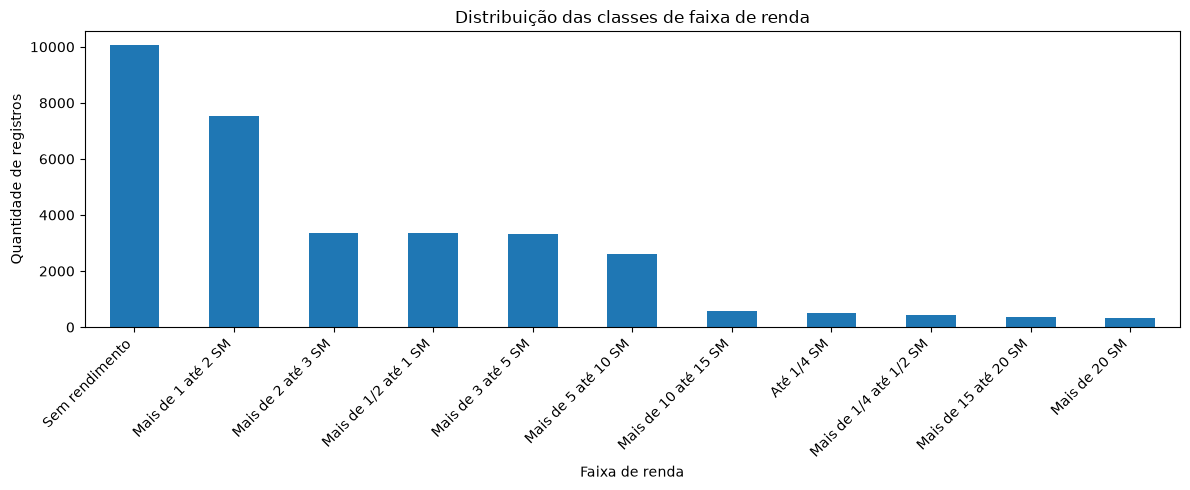

In [435]:

# Contar registros por classe
contagem = df_censo["FAIXA_RENDA"].value_counts()

# Calcular porcentagem de cada classe
porcentagem = df_censo["FAIXA_RENDA"].value_counts(normalize=True) * 100

# Exibir tabela
resultado = pd.DataFrame({
    "Quantidade": contagem,
    "Porcentagem (%)": porcentagem
})

print(resultado.round(2))

# Criar gráfico
resultado["Quantidade"].plot(
    kind="bar",
    figsize=(12, 5),
    title="Distribuição das classes de faixa de renda"
)

plt.xlabel("Faixa de renda")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

A variável `FAIXA_RENDA` apresenta desbalanceamento entre as classes em São Bernardo do Campo. A categoria “Sem rendimento” reúne 10.050 registros (31,01%), enquanto “Mais de 1 até 2 SM” possui 7.525 registros (23,22%). Juntas, representam aproximadamente 54,23% dos registros. Em contraste, “Mais de 20 SM” contém apenas 334 registros (1,03%).

Esse desbalanceamento pode dificultar a classificação no TP2, pois o modelo pode favorecer as classes mais frequentes e apresentar desempenho inferior nas categorias com poucos exemplos. Por isso, avaliar somente a acurácia pode esconder dificuldades na identificação das classes menos frequentes.

Para lidar com essa situação, pode-se utilizar uma divisão estratificada entre treino e teste, preservando a proporção das classes, e avaliar a matriz de confusão, a precisão e o recall por classe, além do F1 macro. Também é possível testar pesos de classe ou técnicas de reamostragem, aplicadas somente aos dados de treinamento.

Os cortes definidos no enunciado devem ser mantidos, pois `FAIXA_RENDA` será a variável-alvo da classificação no TP2.

<div class="alert alert-info">
<b>(0,7) 16</b> - Que atributos são os mais importantes para prever <code>FAIXA_RENDA</code>, considerando correlação absoluta, ANOVA, qui-quadrado, informação mútua e a importância de variáveis segundo uma floresta aleatória? Considere apenas os candidatos da sua cidade de interesse (isso garante que os resultados variem entre equipes).
<br><i>Dica</i>: Para facilitar a visualização, coloque todas as métricas em um único dataframe. Depois normalize-as para que todas fiquem entre 0 e 1. Obtenha então uma média agregada das métricas normalizadas e use essa média para ordenar as variáveis da mais à menos importante.
</div>


,Correlacao_absoluta,ANOVA,Qui_quadrado,Informacao_mutua,Floresta_aleatoria,Media_agregada
Atributo,,,,,,
COD_OCUPACAO,1.0000,1.0000,1.0000,1.0000,0.8534,0.9707
COD_ATIVIDADE_ECON,1.0000,1.0000,1.0000,1.0000,0.7486,0.9497
POSICAO_OCUPACAO,1.0000,1.0000,1.0000,1.0000,0.7165,0.9433
SITUACAO_OCUPACAO,1.0000,1.0000,1.0000,1.0000,0.3798,0.8760
COND_OCUPACAO,1.0000,1.0000,0.8103,1.0000,0.3333,0.8287
COND_ATIVIDADE,0.8605,0.5275,0.8103,0.6685,0.2218,0.6177
SUBGRUPO_OCUPACAO,0.7648,0.4527,0.5859,0.7227,0.4232,0.5899
FAIXA_ETARIA,0.4992,0.1310,0.4493,0.2394,1.0000,0.4638
NIVEL_INSTRUCAO,0.5093,0.1729,0.5258,0.2361,0.8058,0.4500


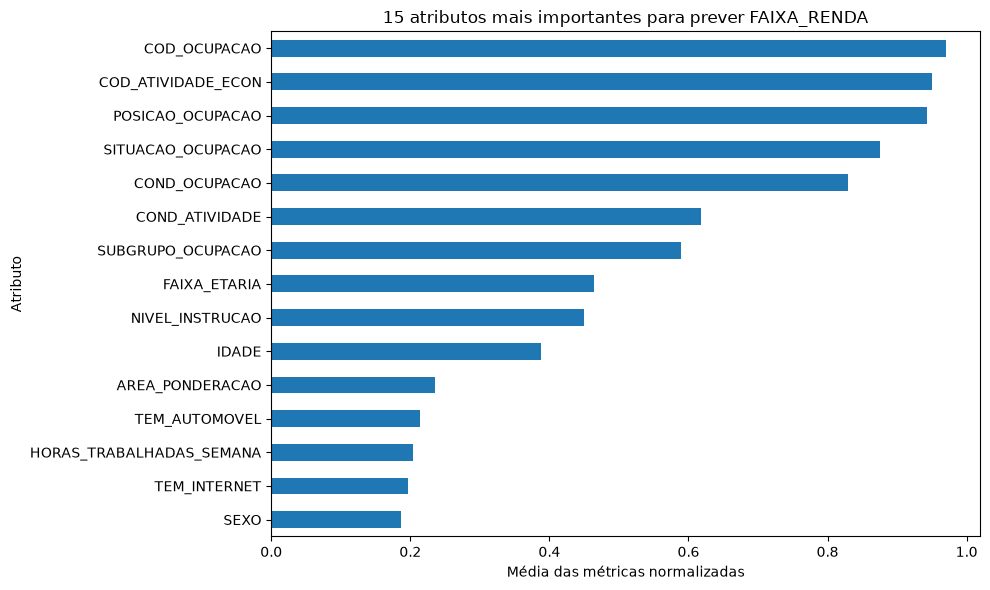

In [436]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_classif, chi2, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

# ==================================================
# 1. PREPARAR OS DADOS
# ==================================================

alvo = "FAIXA_RENDA"

dados = df_censo.loc[
    (df_censo["NOME_MUNICIPIO"] == MUNICIPIO)
    & (df_censo["SIGLA_UF"] == SIGLA_UF)
].copy()

dados = dados.dropna(subset=[alvo]).copy()


# a renda usada para construir FAIXA_RENDA.
colunas_vazamento = [
    c for c in dados.columns
    if c == alvo
    or "RENDA" in c.upper()
    or "FAIXA_RENDA" in c.upper()
]

X = dados.drop(columns=colunas_vazamento, errors="ignore").copy()
ordem_renda = [
    "Sem rendimento",
    "Até 1/4 SM",
    "Mais de 1/4 até 1/2 SM",
    "Mais de 1/2 até 1 SM",
    "Mais de 1 até 2 SM",
    "Mais de 2 até 3 SM",
    "Mais de 3 até 5 SM",
    "Mais de 5 até 10 SM",
    "Mais de 10 até 15 SM",
    "Mais de 15 até 20 SM",
    "Mais de 20 SM"
]

y = pd.Categorical(
    dados[alvo],
    categories=ordem_renda,
    ordered=True
).codes

if (y < 0).any():
    raise ValueError("Existe uma faixa de renda fora das categorias previstas.")

# Remover colunas constantes, vazias e identificadores evidentes.
colunas_remover = [
    c for c in X.columns
    if X[c].nunique(dropna=True) <= 1
    or c.upper() == "ID"
    or c.upper().startswith("ID_")
]

X = X.drop(columns=colunas_remover, errors="ignore")

# Separar atributos categóricos e numéricos.
categoricas_por_codigo = {
    "COD_OCUPACAO",
    "COD_ATIVIDADE_ECON",
    "POSICAO_OCUPACAO",
    "SUBGRUPO_OCUPACAO",
    "NIVEL_INSTRUCAO",
    "COR_RACA",
    "SEXO"
}

categoricas = [
    c for c in X.columns
    if (
        c in categoricas_por_codigo
        or not pd.api.types.is_numeric_dtype(X[c])
        or pd.api.types.is_bool_dtype(X[c])
        or X[c].nunique(dropna=True) <= 15
    )
]

numericas = [c for c in X.columns if c not in categoricas]

# Tratar valores ausentes.
for c in categoricas:
    X[c] = X[c].astype("object").fillna("Ausente").astype(str)

for c in numericas:
    X[c] = pd.to_numeric(X[c], errors="coerce")
    mediana = X[c].median()
    X[c] = X[c].fillna(mediana)

# Remover colunas que não possuem valores válidos.
X = X.dropna(axis=1, how="all")
categoricas = [c for c in categoricas if c in X.columns]
numericas = [c for c in numericas if c in X.columns]

# ==================================================
# 2. CODIFICAR OS ATRIBUTOS
# ==================================================

preprocessador = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
    ],
    remainder="drop"
)

X_enc = preprocessador.fit_transform(X)

# Identificar o atributo original de cada coluna codificada.
origem_features = list(numericas)
mascara_discreta = [False] * len(numericas)

encoder = preprocessador.named_transformers_["cat"]

for coluna, categorias_coluna in zip(categoricas, encoder.categories_):
    origem_features.extend([coluna] * len(categorias_coluna))
    mascara_discreta.extend([True] * len(categorias_coluna))

mascara_discreta = np.array(mascara_discreta, dtype=bool)

# Converter para matriz densa para corrigir o erro da informação mútua.
# A conversão é necessária para a função receber atributos contínuos.
X_dense = X_enc.toarray() if hasattr(X_enc, "toarray") else np.asarray(X_enc)

# ==================================================
# 3. CALCULAR AS CINCO MÉTRICAS
# ==================================================

# Correlação absoluta entre cada atributo codificado e o alvo.
scores_corr = []

for j in range(X_dense.shape[1]):
    coluna = X_dense[:, j]

    if np.std(coluna) == 0 or np.std(y) == 0:
        scores_corr.append(0.0)
    else:
        corr = np.corrcoef(coluna, y)[0, 1]
        scores_corr.append(abs(corr) if np.isfinite(corr) else 0.0)

scores_corr = np.array(scores_corr)

# ANOVA
scores_anova, _ = f_classif(X_dense, y)
scores_anova = np.nan_to_num(
    scores_anova, nan=0.0, posinf=0.0, neginf=0.0
)

# Qui-quadrado
scores_chi2, _ = chi2(X_dense, y)
scores_chi2 = np.nan_to_num(
    scores_chi2, nan=0.0, posinf=0.0, neginf=0.0
)

# Informação mútua — matriz densa para evitar o erro anterior.
scores_mi = mutual_info_classif(
    X_dense,
    y,
    discrete_features=mascara_discreta,
    random_state=42
)
scores_mi = np.nan_to_num(
    scores_mi, nan=0.0, posinf=0.0, neginf=0.0
)

# Floresta aleatória
modelo = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced_subsample",
    min_samples_leaf=3,
    n_jobs=-1
)

modelo.fit(X_dense, y)
scores_rf = modelo.feature_importances_

# ==================================================
# 4. AGRUPAR MÉTRICAS POR ATRIBUTO ORIGINAL
# ==================================================

metricas = pd.DataFrame({
    "Atributo": origem_features,
    "Correlacao_absoluta": scores_corr,
    "ANOVA": scores_anova,
    "Qui_quadrado": scores_chi2,
    "Informacao_mutua": scores_mi,
    "Floresta_aleatoria": scores_rf
})

# Para as categorias codificadas, somar a importância da floresta.
# Nas outras métricas, usar o maior escore entre as categorias.
resultado = metricas.groupby("Atributo").agg({
    "Correlacao_absoluta": "max",
    "ANOVA": "max",
    "Qui_quadrado": "max",
    "Informacao_mutua": "max",
    "Floresta_aleatoria": "sum"
})

# ==================================================
# 5. NORMALIZAR ENTRE 0 E 1 E CALCULAR A MÉDIA
# ==================================================

colunas_metricas = resultado.columns

for coluna in colunas_metricas:
    minimo = resultado[coluna].min()
    maximo = resultado[coluna].max()

    if maximo > minimo:
        resultado[coluna] = (
            (resultado[coluna] - minimo) / (maximo - minimo)
        )
    else:
        resultado[coluna] = 0.0

resultado["Media_agregada"] = resultado[colunas_metricas].mean(axis=1)

resultado = resultado.sort_values(
    "Media_agregada",
    ascending=False
)

# Mostrar a tabela completa, da variável mais importante à menos importante.
display(resultado.round(4))

# ==================================================
# 6. GRÁFICO DOS 15 ATRIBUTOS MAIS IMPORTANTES
# ==================================================

resultado["Media_agregada"].head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="15 atributos mais importantes para prever FAIXA_RENDA"
)

plt.xlabel("Média das métricas normalizadas")
plt.ylabel("Atributo")
plt.tight_layout()
plt.show()

<div class="alert alert-primary">
<b>(0,5) 16.1</b> - Explique os resultados obtidos. As cinco métricas concordam entre si? Alguma posição no ranking te surpreendeu, para cima ou para baixo? Isso muda sua decisão sobre quais atributos usar no TP2?
</div>


A análise foi realizada apenas com os registros de São Bernardo do Campo. Pela média das cinco métricas normalizadas, os atributos mais importantes foram `COD_OCUPACAO` (0,9707), `COD_ATIVIDADE_ECON` (0,9497), `POSICAO_OCUPACAO` (0,9433), `SITUACAO_OCUPACAO` (0,8760) e `COND_OCUPACAO` (0,8287). Assim, as informações relacionadas ao trabalho e à ocupação se destacaram na associação com `FAIXA_RENDA`.

As cinco métricas concordam parcialmente. Os atributos de ocupação apresentam resultados elevados em várias delas, mas existem diferenças importantes. Por exemplo, `FAIXA_ETARIA` teve a maior importância normalizada na floresta aleatória, enquanto apresentou valores menores nas outras métricas. `IDADE` também se destacou mais na floresta e na informação mútua do que na ANOVA e no qui-quadrado. Isso indica que a importância de um atributo depende da forma como sua relação com o alvo é avaliada. Os valores iguais a 1 representam o máximo após a normalização, não uma associação perfeita.

Uma posição que chamou atenção foi a de `NIVEL_INSTRUCAO`, em nono lugar, abaixo de vários atributos de ocupação, apesar da relação entre escolaridade e renda observada anteriormente. `SEXO` e `COR_RACA` também ficaram em posições inferiores. Isso não contradiz as desigualdades descritas nas questões anteriores, pois diferenças de renda entre grupos não implicam necessariamente elevada capacidade de prever individualmente a faixa de renda.

O destaque dos códigos de ocupação e atividade econômica exige cuidado. Como as métricas das categorias foram agregadas pelo maior escore, parte do resultado pode estar associada à categoria “Ausente”, compartilhada por variáveis de trabalho. Além disso, a importância da floresta pode favorecer atributos com muitas categorias. Portanto, o ranking é exploratório e não demonstra causalidade nem desempenho em dados novos.

Para o TP2, os resultados orientam a inclusão de atributos de ocupação, escolaridade e idade como candidatos, mas não justificam excluir automaticamente os demais. Também será necessário avaliar a redundância entre `IDADE` e `FAIXA_ETARIA`, escolher uma codificação adequada para os atributos de alta cardinalidade e revisar identificadores e variáveis técnicas. A seleção final deverá ser feita com validação nos dados de treinamento, mantendo as variáveis de renda que revelam diretamente o alvo fora dos preditores.

---

#### Comunicação e storytelling


<div class="alert alert-info">
<b>(1,5) 17</b> - Produza um vídeo de até 3 minutos, com narração (voiceover), contando uma única história a partir dos achados do TP1, para uma audiência do seu município de interesse (ex.: um gestor público local, um jornalista da cidade). Escolha 2 achados das questões 7 a 12 (que comparam seu município com o resto do país) que juntos sustentem essa mensagem central (a "big idea"); não tente encaixar todos os achados do trabalho, isso é ruído, não sinal. Como a audiência e os dados são específicos da sua cidade, a história precisa fazer sentido para o seu recorte. Aplique os princípios de storytelling with data vistos no curso: contexto da audiência, uma mensagem central clara, remoção de excesso visual (declutter), uso de foco/destaque (cor, texto, posição) para guiar o olhar e um arco narrativo (contexto -> tensão/descoberta -> conclusão). <b>Vídeos com mais de 3 minutos não serão avaliados</b>. A equipe é responsável por conferir a duração antes de entregar.

Poste o vídeo no YouTube (não listado) ou Google Drive (com compartilhamento "qualquer pessoa com o link pode assistir") e inclua o link nesta célula. Não envie o arquivo de vídeo diretamente pelo Classroom. Exporte em resolução moderada (720p já é suficiente) para manter o arquivo pequeno.
<br><i>Dica</i>: o vídeo costuma ser a parte com a curva de aprendizado mais alta pra quem nunca gravou/editou narração antes. Não deixe pra fazer na última semana. Uma boa prática é, na metade do prazo, já ter escolhido os 2 achados e um rascunho do roteiro, mesmo que o resto do TP1 ainda não esteja pronto.

</div>


<div class="alert alert-primary">
<b>(0,5) 17.1</b> - Em 3-4 frases, justifique as escolhas de design que você fez: por que esse recorte de achados, qual é a "big idea", e qual elemento de storytelling with data você usou mais deliberadamente?
</div>
